# 02 · Parser and PC algorithm
**Owner:** Rakshita

Turn every premise and hypothesis into structured facts (`src/parser.py`), then run the PC algorithm (`src/pc.py`)
to recover the causal graph behind each premise.

The parser and PC are fixed rules that never learn from data, so running them on all three splits is not leakage.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"

from src.parser import ParseError, parse_hypothesis, parse_premise
from src.pc import markov_equivalence_class, relation_support, run_pc

splits = {s: pd.read_csv(PROCESSED / f"{s}.csv") for s in ["train", "validation", "test"]}

## 1. Parse one example
The text is generated from templates, so a few regular expressions are enough.

In [2]:
row = splits["test"].query("num_variables == 3").iloc[0]
print(row["premise"])
facts = parse_premise(row["premise"])
print("\nvariables:     ", facts.variables)
print("correlations:  ", sorted("-".join(sorted(p)) for p in facts.correlations))
print("independencies:", [(x, y, sorted(g)) for x, y, g in facts.independencies])
print("\nhypothesis:", row["hypothesis"], "->", parse_hypothesis(row["hypothesis"], facts.variables))

Suppose there is a closed system of 3 variables, A, B and C. All the statistical relations among these 3 variables are as follows: A correlates with C. B correlates with C. However, A is independent of B.

variables:      ['A', 'B', 'C']
correlations:   ['A-C', 'B-C']
independencies: [('A', 'B', [])]

hypothesis: There exists at least one collider (i.e., common effect) of B and C. -> HypothesisFacts(relation='collider', x='B', y='C')


## 2. Schema rules
Only the variables A–F are allowed and self-loops (A → A) are rejected. Some broken inputs to show the parser catches them:

In [3]:
broken = {
    "self-loop": lambda: parse_hypothesis("C directly causes C."),
    "variable outside A-F": lambda: parse_hypothesis("A directly causes G."),
    "variable not in premise": lambda: parse_hypothesis("A directly causes F.", variables=facts.variables),
    "unknown wording": lambda: parse_hypothesis("A and B are friends."),
}
for name, call in broken.items():
    try:
        call()
        print(f"{name:<25} NOT caught")
    except ParseError as err:
        print(f"{name:<25} rejected -> {err}")

self-loop                 rejected -> self-loop hypothesis: C directly causes C.
variable outside A-F      rejected -> variable 'G' is outside the A-F schema
variable not in premise   rejected -> variable 'F' is not declared in the premise
unknown wording           rejected -> hypothesis does not match any known template: A and B are friends.


## 3. Parse every row

In [4]:
parsed = {}
for name, df in splits.items():
    premises = {pid: parse_premise(p) for pid, p in zip(df["premise_id"], df["premise"])}
    hyps = [parse_hypothesis(h, premises[pid].variables) for pid, h in zip(df["premise_id"], df["hypothesis"])]
    parsed[name] = (premises, hyps)
    print(f"{name:<11} {len(df)} rows parsed, {len(premises)} premises, 0 errors")

train       35340 rows parsed, 400 premises, 0 errors
validation  1026 rows parsed, 19 premises, 0 errors
test        1162 rows parsed, 21 premises, 0 errors


In [5]:
# check: each dataset template maps to exactly one parsed relation
check = pd.DataFrame({
    "template": pd.concat([df["template"] for df in splits.values()], ignore_index=True),
    "relation": [h.relation for _, hyps in parsed.values() for h in hyps],
})
pd.crosstab(check["template"], check["relation"])

relation,collider,confounder,direct_cause,indirect_cause
template,,,,
child,0,0,6253,0
has_collider,6259,0,0,0
has_confounder,0,6259,0,0
non-child descendant,0,0,0,6291
non-parent ancestor,0,0,0,6214
parent,0,0,6252,0


"parent" and "child" both become `direct_cause` because their text is the same.

## 4. Parser tests

In [6]:
result = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "--color=no", "-p", "no:cacheprovider"],
                        cwd=ROOT, capture_output=True, text=True)
print(result.stdout[-300:])

.................                                                        [100%]
17 passed in 0.08s



## 5. PC algorithm
PC usually tests independence on numeric data. Here the premise already states the independences, so we use them directly:
1. start with all variables connected and remove edges between independent pairs
2. find colliders (X → Z ← Y)
3. orient the remaining edges where only one direction is possible

Edges whose direction can't be decided stay undirected (dashed in the plot).

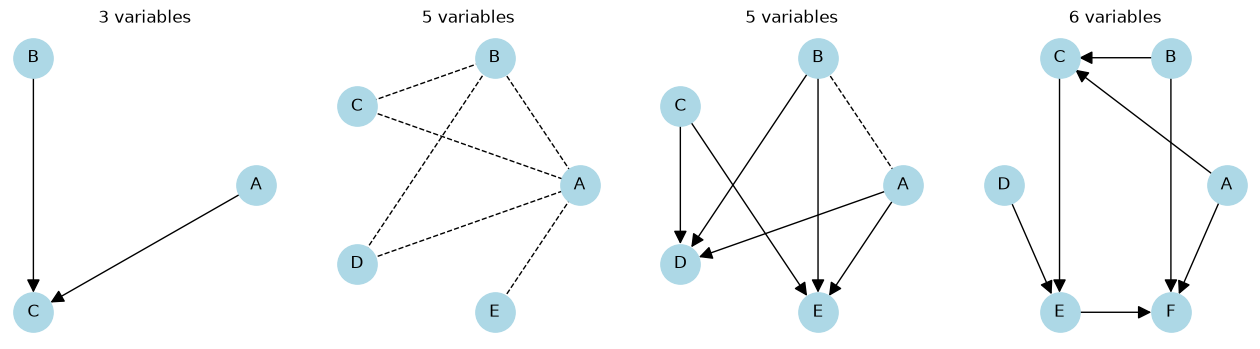

In [7]:
def draw(cpdag, ax, title):
    g = nx.DiGraph()
    g.add_nodes_from(cpdag.nodes)
    pos = nx.circular_layout(g)
    nx.draw_networkx_nodes(g, pos, ax=ax, node_color="lightblue", node_size=800)
    nx.draw_networkx_labels(g, pos, ax=ax)
    nx.draw_networkx_edges(g, pos, edgelist=list(cpdag.directed), ax=ax, arrowsize=20, node_size=800)
    nx.draw_networkx_edges(g, pos, edgelist=[tuple(e) for e in cpdag.undirected], ax=ax, arrows=False, style="dashed")
    ax.set_title(title)
    ax.axis("off")


examples = splits["test"].drop_duplicates("premise_id").sort_values("num_variables").iloc[[1, 6, 12, 18]]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (pid, n) in zip(axes, zip(examples["premise_id"], examples["num_variables"])):
    draw(run_pc(parsed["test"][0][pid]), ax, f"{n} variables")
plt.show()

## 6. Do the graphs explain the labels?
A hypothesis is valid if it holds in every graph that fits the premise. We check this for every row.

In [8]:
graph_rows, agreement = [], []
for name, df in splits.items():
    premises, hyps = parsed[name]
    mecs = {}
    for pid, f in premises.items():
        cpdag = run_pc(f)
        mecs[pid] = markov_equivalence_class(cpdag)
        graph_rows.append({"premise_id": pid, "split": name, "variables": ",".join(f.variables),
                           "directed_edges": ";".join(f"{a}->{b}" for a, b in sorted(cpdag.directed)),
                           "mec_size": len(mecs[pid])})
    rule = [int(relation_support(mecs[pid], h.relation, h.x, h.y) == 1) for pid, h in zip(df["premise_id"], hyps)]
    agreement.append(df[["template", "label"]].assign(split=name, agrees=(pd.Series(rule) == df["label"])))

agreement = pd.concat(agreement)
agreement.pivot_table(index="template", columns="split", values="agrees").round(3)

split,test,train,validation
template,,,
child,1.000,1.000,1.000
has_collider,0.933,0.888,0.903
has_confounder,0.979,0.960,0.989
non-child descendant,0.964,0.932,0.994
non-parent ancestor,0.938,0.925,0.976
parent,0.959,0.917,0.929


In [9]:
agreement.groupby("split")["agrees"].mean().round(3)

split
test          0.962
train         0.937
validation    0.965
Name: agrees, dtype: float64

The parser + PC reproduce about 94–96% of the labels, so the parsing is correct. The rest are cases where the
dataset's label differs from what PC concludes. We treat that as a limitation of the dataset.

## 7. Save the graphs

In [10]:
pd.DataFrame(graph_rows).to_csv(PROCESSED / "premise_graphs.csv", index=False)
print("saved data/processed/premise_graphs.csv")

saved data/processed/premise_graphs.csv
